## 1. Problem framing
The objective is to predict whether a customer will churn using the customer churn dataset. This is a supervised binary classification problem, with `Churn` as the target variable (0 = No Churn, 1 = Churn).

In [53]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 2. Load the dataset and inspect its structure


In [54]:
df = pd.read_csv("customer_churn_1000.csv")

print("Dataset shape:", df.shape)
display(df.head())
display(df.info())
display(df.describe(include="all").T)

Dataset shape: (1000, 12)


,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,15477,55,Male,20,24,4,6,Standard,Monthly,635,25,0
1,34667,28,Male,27,30,4,5,Premium,Quarterly,631,10,0
2,50475,65,Female,60,17,7,16,Premium,Quarterly,314,1,1
3,7985,53,Male,47,16,8,7,Premium,Annual,527,13,0
4,20228,32,Male,56,5,7,15,Premium,Annual,236,25,0


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   CustomerID         1000 non-null   int64
 1   Age                1000 non-null   int64
 2   Gender             1000 non-null   str  
 3   Tenure             1000 non-null   int64
 4   Usage Frequency    1000 non-null   int64
 5   Support Calls      1000 non-null   int64
 6   Payment Delay      1000 non-null   int64
 7   Subscription Type  1000 non-null   str  
 8   Contract Length    1000 non-null   str  
 9   Total Spend        1000 non-null   int64
 10  Last Interaction   1000 non-null   int64
 11  Churn              1000 non-null   int64
dtypes: int64(9), str(3)
memory usage: 93.9 KB


None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,1000.0,NaN,NaN,NaN,32756.895,18285.820866,115.0,16990.75,33142.0,48099.5,64268.0
Age,1000.0,NaN,NaN,NaN,41.748,13.764009,18.0,30.0,41.0,54.0,65.0
Gender,1000,2,Female,541,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tenure,1000.0,NaN,NaN,NaN,32.918,16.845862,1.0,19.0,34.0,47.0,60.0
Usage Frequency,1000.0,NaN,NaN,NaN,14.811,8.754995,1.0,7.0,14.0,23.0,30.0
Support Calls,1000.0,NaN,NaN,NaN,5.453,3.101517,0.0,3.0,6.0,8.0,10.0
Payment Delay,1000.0,NaN,NaN,NaN,17.001,8.948356,0.0,10.0,19.0,25.0,30.0
Subscription Type,1000,3,Premium,349,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Contract Length,1000,3,Monthly,342,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Total Spend,1000.0,NaN,NaN,NaN,547.528,268.957222,101.0,313.25,553.0,783.0,1000.0


## 3. Data quality checks

In [55]:
print("Duplicate rows:", df.duplicated().sum())
print("\\nMissing values per column:")
display(df.isna().sum().to_frame("missing_count"))

print("\\nTarget distribution:")
display(df["Churn"].value_counts().sort_index().to_frame("count"))
display((df["Churn"].value_counts(normalize=True).sort_index() * 100).round(2).to_frame("percentage"))


Duplicate rows: 0
\nMissing values per column:


,missing_count
CustomerID,0
Age,0
Gender,0
Tenure,0
Usage Frequency,0
Support Calls,0
Payment Delay,0
Subscription Type,0
Contract Length,0
Total Spend,0


\nTarget distribution:


,count
Churn,
0,527
1,473


,percentage
Churn,
0,52.7
1,47.3


### Initial data-quality interpretation

In the supplied CSV, the data has 1,000 rows and 12 columns. Initial inspection shows no missing values. The notebook still includes imputers in the pipeline so it remains robust if missing values appear in later data or during a future update. Duplicate rows and the target distribution are checked above rather than assumed.

## 4. Exploratory data analysis (EDA) — three visualisations

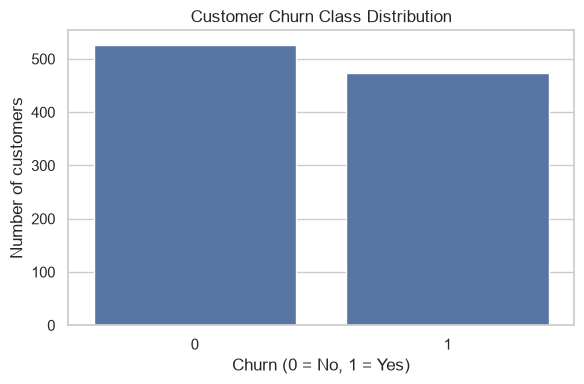

In [56]:
# Visualisation 1: target/class distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Class Distribution")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

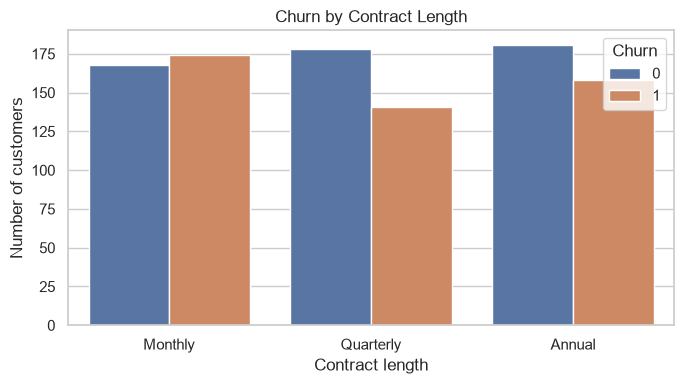

In [57]:
# Visualisation 2: churn by contract length
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Contract Length", hue="Churn")
plt.title("Churn by Contract Length")
plt.xlabel("Contract length")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

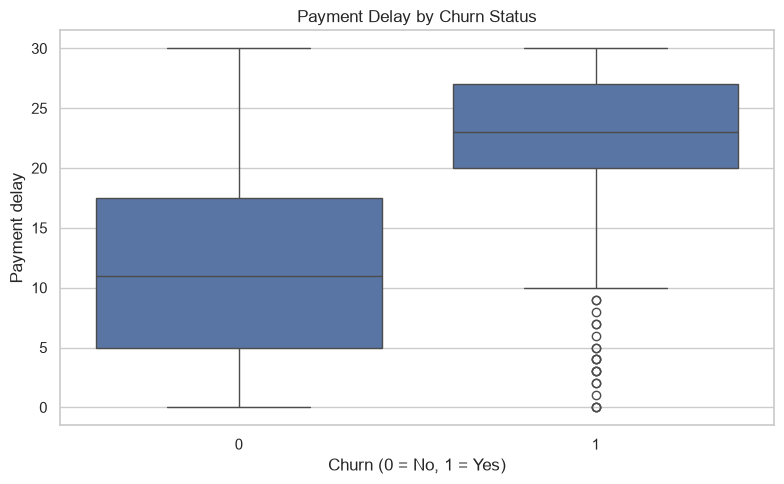

In [58]:
# Visualisation 3: numeric feature distributions by churn
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Churn", y="Payment Delay")
plt.title("Payment Delay by Churn Status")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Payment delay")
plt.tight_layout()
plt.show()

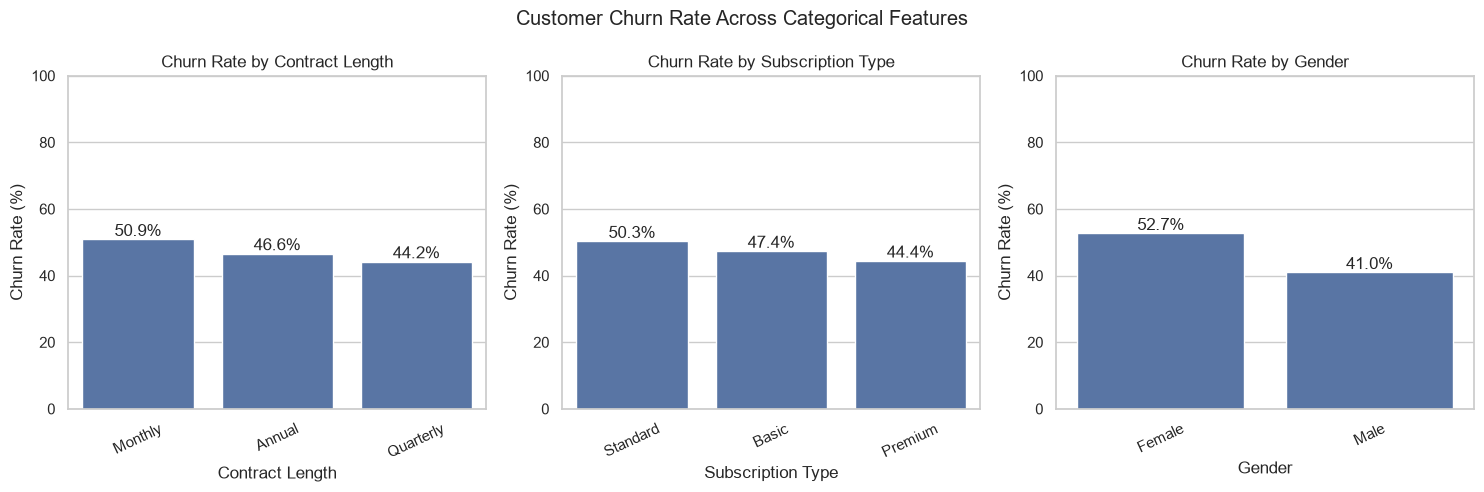

In [59]:
## Categorical churn-rate analysis
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

categorical_groups = [
    "Contract Length",
    "Subscription Type",
    "Gender"
]

for ax, column in zip(axes, categorical_groups):
    churn_rates = (
        df.groupby(column, observed=True)["Churn"]
        .mean()
        .mul(100)
        .sort_values(ascending=False)
    )

    sns.barplot(
        x=churn_rates.index,
        y=churn_rates.values,
        ax=ax
    )

    ax.set_title(f"Churn Rate by {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Churn Rate (%)")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=25)

    for i, rate in enumerate(churn_rates.values):
        ax.text(i, rate + 1, f"{rate:.1f}%", ha="center")

plt.suptitle("Customer Churn Rate Across Categorical Features")
plt.tight_layout()
plt.show()


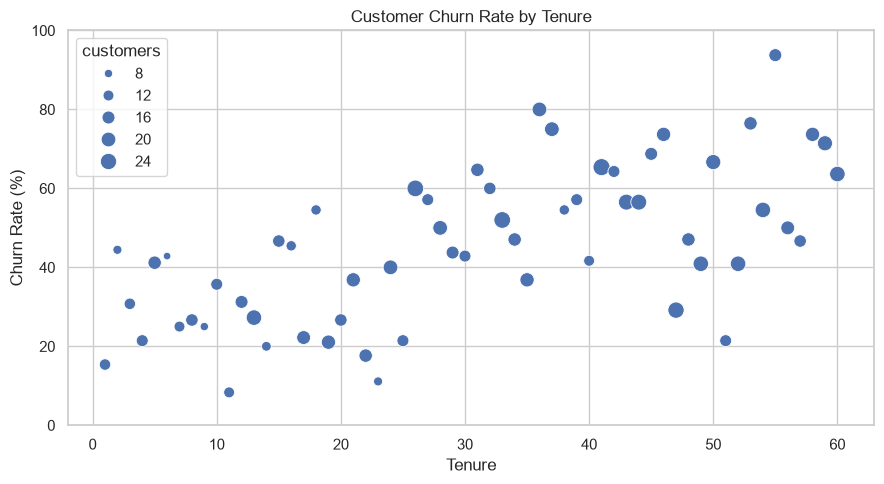

In [60]:

# Analyse churn rate across customer tenure
tenure_churn = (
    df.groupby("Tenure", observed=True)["Churn"]
    .agg(customers="count", churn_rate="mean")
    .reset_index()
)
tenure_churn["churn_rate"] = tenure_churn["churn_rate"] * 100
plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=tenure_churn,
    x="Tenure",
    y="churn_rate",
    size="customers",
    sizes=(30, 150)
)
plt.title("Customer Churn Rate by Tenure")
plt.xlabel("Tenure")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

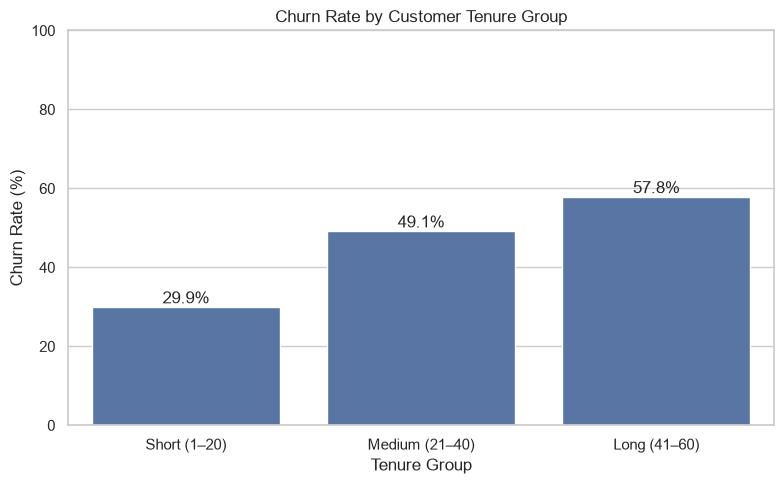

In [61]:

# Churn rate by tenure group

df["Tenure Group"] = pd.cut(
    df["Tenure"],
    bins=[0, 20, 40, 60],
    labels=["Short (1–20)", "Medium (21–40)", "Long (41–60)"]
)

tenure_summary = (
    df.groupby("Tenure Group", observed=True)["Churn"]
    .mean()
    .mul(100)
    .reset_index(name="Churn Rate (%)")
)

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=tenure_summary,
    x="Tenure Group",
    y="Churn Rate (%)"
)

plt.title("Churn Rate by Customer Tenure Group")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)

for i, rate in enumerate(tenure_summary["Churn Rate (%)"]):
    ax.text(i, rate + 1, f"{rate:.1f}%", ha="center")

plt.tight_layout()
plt.show()


### EDA interpretation
The dataset has a fairly balanced churn distribution, with 52.7% non-churned and 47.3% churned customers. Monthly-contract customers show a higher churn rate than annual and quarterly-contract customers. The plots also help compare payment delays between churn groups and explore churn rates across subscription types, gender, and tenure. These patterns show associations and do not establish causation.

## 5. Outlier screening

In [62]:
# IQR screening is used to flag possible outliers, not automatically delete them.
numeric_for_outliers = df.select_dtypes(include=np.number).drop(columns=["CustomerID", "Churn"], errors="ignore")
outlier_summary = []

for col in numeric_for_outliers.columns:
    q1 = numeric_for_outliers[col].quantile(0.25)
    q3 = numeric_for_outliers[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((numeric_for_outliers[col] < lower) | (numeric_for_outliers[col] > upper)).sum()
    outlier_summary.append({
        "feature": col, "lower_IQR_bound": lower,
        "upper_IQR_bound": upper, "flagged_rows": int(count)
    })

outlier_summary = pd.DataFrame(outlier_summary)
display(outlier_summary)

,feature,lower_IQR_bound,upper_IQR_bound,flagged_rows
0,Age,-6.000,90.000,0
1,Tenure,-23.000,89.000,0
2,Usage Frequency,-17.000,47.000,0
3,Support Calls,-4.500,15.500,0
4,Payment Delay,-12.500,47.500,0
5,Total Spend,-391.375,1487.625,0
6,Last Interaction,-14.500,45.500,0


### Outlier decision

The IQR rule flags unusual values for review; it does not prove that they are errors. Customer behaviour such as high support calls or payment delays may be real and useful for churn prediction, so this project does not automatically remove flagged rows. Any value removal or capping should be justified and performed using training data only.

## 6. Prepare features and target
The target variable is `Churn`, while `CustomerID` is excluded because it is an identifier rather than a predictive feature. The remaining features are separated into numerical and categorical groups so that appropriate preprocessing can be applied to each.

In [66]:
TARGET = "Churn"
ID_COLUMNS = ["CustomerID"]

X = df.drop(columns=[TARGET] + ID_COLUMNS, errors="ignore")
y = df[TARGET].astype(int)

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Target classes:", sorted(y.unique()))

Numeric features: ['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Total Spend', 'Last Interaction']
Categorical features: ['Gender', 'Subscription Type', 'Contract Length', 'Tenure Group']
Target classes: [np.int64(0), np.int64(1)]


## 7. Stratified train/test split

The target is stratified so that the class proportions are approximately preserved in both subsets. The split occurs **before** fitting preprocessing transformations. The test set is held aside and must not be used to learn imputation values, scaling parameters, or category mappings.

In [64]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)
print("\\nTraining target proportions:")
display(y_train.value_counts(normalize=True).sort_index().to_frame("proportion"))
print("\\nTest target proportions:")
display(y_test.value_counts(normalize=True).sort_index().to_frame("proportion"))

Training features: (800, 11)
Test features: (200, 11)
\nTraining target proportions:


,proportion
Churn,
0,0.5275
1,0.4725


\nTest target proportions:


,proportion
Churn,
0,0.525
1,0.475


## 8. Leakage-free preprocessing pipeline
A `ColumnTransformer` applies separate preprocessing pipelines to numerical and categorical features. Numerical features are imputed using the median and scaled, while categorical features are imputed using the most frequent value and one-hot encoded. The preprocessor is fitted only on the training data and then applied to the test data to prevent data leakage.

In [65]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Fit transformations on training data only; transform test data without refitting.
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print("Prepared training matrix shape:", X_train_prepared.shape)
print("Prepared test matrix shape:", X_test_prepared.shape)
print("Pipeline successfully fitted on training data only.")


Prepared training matrix shape: (800, 18)
Prepared test matrix shape: (200, 18)
Pipeline successfully fitted on training data only.
